# 1. Equal-Width Binning

Let's start with the simplest technique.

## What does "Equal-Width" mean?

The word **width** is the key.

> **Equal-Width Binning divides the entire numerical range into bins having equal interval widths.**

It does **not** try to put the same number of observations into every bin.

## Example

Consider the following student marks:

```text
12, 18, 45, 67, 71, 72, 78, 82, 85, 88, 91, 95

In [3]:
import pandas as pd
import numpy as np

# Sample student marks data
marks = [12, 18, 45, 67, 71, 72, 78, 82, 85, 88, 91, 95]
df = pd.DataFrame({'marks': marks})
df


,marks
0,12
1,18
2,45
3,67
4,71
5,72
6,78
7,82
8,85
9,88


In [ ]:
print("Original marks:")
print(df['marks'].tolist())

## Data Range

The data range is:

- Minimum = **12**
- Maximum = **95**
- Number of bins = **3**

### Calculate Bin Width

The formula for calculating equal-width bin size is:

$$
\text{Bin Width} = \frac{\text{Max} - \text{Min}}{\text{Number of bins}}
$$

Substituting the values:

$$
= \frac{95 - 12}{3}
$$

$$
= \frac{83}{3} = 27.67
$$

Therefore, the three equal-width intervals are approximately:

| Bin | Interval | Grade |
|:---:|:---------|:------|
| 1 | 12 – 39.67 | Low |
| 2 | 39.67 – 67.33 | Medium |
| 3 | 67.33 – 95 | High |

### Examples

Based on these intervals:

- **12** → **Low**
- **18** → **Low**
- **45** → **Medium**
- **67** → **Medium**
- **71** → **High**
- **72** → **High**
- **78** → **High**
- **...** → **High**
### Equal-width does NOT mean equal number of observations in each bin.

#### pd.cut() Create Equal-Width Bins

In [2]:
# pd.cut(df["marks"], bins=3, labels=["Low", "Medium", "High"])
df['grade_equalwidth'] = pd.cut(
    df['marks'],
    bins=3,                          # number of bins
    labels=['Low', 'Medium', 'High'] # names for each bin
)

print("Equal-Width Binning result:")
print(df[['marks', 'grade_equalwidth']])

Equal-Width Binning result:
    marks grade_equalwidth
0      12              Low
1      18              Low
2      45              Low
3      67              Low
4      71              Low
5      72              Low
6      78              Low
7      82              Low
8      85              Low
9      88              Low
10     91              Low
11     95              Low
12   1000             High


In [9]:
print("\nHow many students in each bin?")
print(df['grade_equalwidth'].value_counts().sort_index())


How many students in each bin?
grade_equalwidth
Low       2
Medium    2
High      8
Name: count, dtype: int64


<Axes: xlabel='grade_equalwidth'>

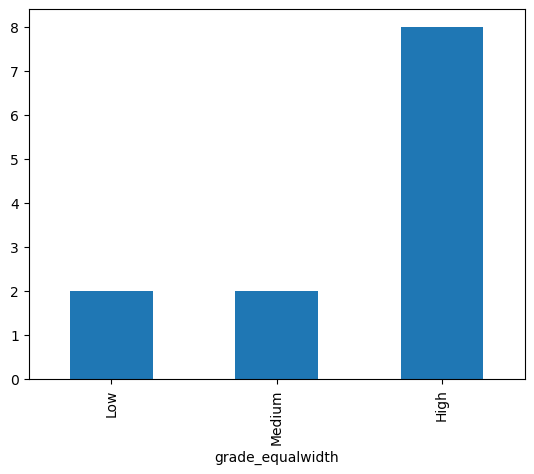

In [7]:
import matplotlib.pyplot as plt
df["grade_equalwidth"].value_counts().sort_index().plot(kind="bar")

In [10]:
# complete program
import pandas as pd

# Student marks
marks = [12, 18, 45, 67, 71, 72, 78, 82, 85, 88, 91, 95]

# Create DataFrame
df = pd.DataFrame({"marks": marks})

# Equal-Width Binning
df["grade_equalwidth"] = pd.cut(
    df["marks"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

# Display result
print(df)

    marks grade_equalwidth
0      12              Low
1      18              Low
2      45           Medium
3      67           Medium
4      71             High
5      72             High
6      78             High
7      82             High
8      85             High
9      88             High
10     91             High
11     95             High


# Equal-Width Binning

> **Equal-Width Binning divides the numerical range into intervals of equal width and assigns each observation to the interval in which it falls.**

## Key Points

- **Equal width** means that every bin covers the same numerical range.
- The **minimum and maximum values** determine the overall range of the data.
- The range is divided into the required **number of bins**.

## Remember

**Equal-Width → Equal interval size, NOT equal number of observations.**

In [11]:
custom_bins   = [0, 39, 59, 74, 89, 100]
custom_labels = ['F', 'D', 'C', 'B', 'A']

df['grade_custom'] = pd.cut(
    df['marks'],
    bins=custom_bins,
    labels=custom_labels
)

print("Custom Binning (Exam Grade Style):")
print(df[['marks', 'grade_custom']])

Custom Binning (Exam Grade Style):
    marks grade_custom
0      12            F
1      18            F
2      45            D
3      67            C
4      71            C
5      72            C
6      78            B
7      82            B
8      85            B
9      88            B
10     91            A
11     95            A
